# Grover vs. classical search

**Question.** How many times do we have to ask the "is this a solution?" question to find a solution, classically and with Grover?

**Classical random search.** $N$ boxes, $k$ of them contain a prize. We open boxes in a random order, never opening a box twice, and stop as soon as we find a prize.
On average this takes

$$\text{classical checks} = \frac{N+1}{k+1} \;\approx\; \frac{N}{k} \text{ for large } N.$$

(For $k = 1$ that's about $N/2$: on average the prize is halfway through the list.)

**Grover.** One run uses $r_\text{opt}$ oracle queries (one per round) and then measures. It finds a solution with probability $P = \sin^2((2r_\text{opt}+1)\theta)$, which is high but not always 100%.
If it fails, we simply run it again. On average this needs $1/P$ runs, so the **expected number of queries including retries** is $r_\text{opt}/P$.
For large $N$:

$$\text{Grover queries} \;\approx\; \frac{\pi}{4}\sqrt{\frac{N}{k}}.$$

**Expected result.** Classical search grows like $N$, Grover like $\sqrt{N}$: a **quadratic speed-up**. On a log-log plot both are straight lines, the Grover line with half the slope.

We do this for $N = 4, 8, \dots, 1024$ ($n = 2 \dots 10$ qubits) and $k = 1$ and $k = 4$ solutions.
The classical search is plain Python (the `random` module).

In [6]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%run grover_core.ipynb   # we only use optimal_iterations and theoretical_success (pure formulas, no circuits)

os.makedirs("figures", exist_ok=True)

random.seed(42)
N_QUBITS = list(range(2, 11))            # n = 2 ... 10
N_VALUES = [2 ** n for n in N_QUBITS]    # N = 4 ... 1024
K_VALUES = [1, 4]
TRIALS = 10_000                          # classical searches averaged per (N, k)

In [7]:
def classical_search(N, k):
    """Open boxes in random order (no repeats) until a prize is found; return the number of boxes opened."""
    prizes = set(random.sample(range(N), k))
    boxes = list(range(N))
    for i in range(N):
        j = random.randrange(i, N)                 # pick a random unopened box ...
        boxes[i], boxes[j] = boxes[j], boxes[i]    # ... and move it to position i
        if boxes[i] in prizes:                     # one check = one oracle query
            return i + 1
    raise RuntimeError("no prize found (impossible for k >= 1)")


classical = {}
for k in K_VALUES:
    classical[k] = []
    for N in N_VALUES:
        checks = [classical_search(N, k) for _ in range(TRIALS)]
        classical[k].append((np.mean(checks), np.std(checks) / math.sqrt(TRIALS)))

print(f"average number of checks over {TRIALS} searches (± standard error of the mean)")
for k in K_VALUES:
    print(f"\nk = {k}")
    print("     N | simulated          | theory (N+1)/(k+1)")
    for N, (m, se) in zip(N_VALUES, classical[k]):
        print(f"{N:6d} | {m:8.2f} ± {se:5.2f}   | {(N + 1) / (k + 1):8.2f}")

average number of checks over 10000 searches (± standard error of the mean)

k = 1
     N | simulated          | theory (N+1)/(k+1)
     4 |     2.51 ±  0.01   |     2.50
     8 |     4.52 ±  0.02   |     4.50
    16 |     8.50 ±  0.05   |     8.50
    32 |    16.47 ±  0.09   |    16.50
    64 |    32.25 ±  0.18   |    32.50
   128 |    64.71 ±  0.37   |    64.50
   256 |   129.28 ±  0.74   |   128.50
   512 |   256.91 ±  1.47   |   256.50
  1024 |   518.26 ±  2.95   |   512.50

k = 4
     N | simulated          | theory (N+1)/(k+1)
     4 |     1.00 ±  0.00   |     1.00
     8 |     1.81 ±  0.01   |     1.80
    16 |     3.40 ±  0.02   |     3.40
    32 |     6.65 ±  0.05   |     6.60
    64 |    13.04 ±  0.10   |    13.00
   128 |    25.91 ±  0.21   |    25.80
   256 |    50.79 ±  0.42   |    51.40
   512 |   103.77 ±  0.84   |   102.60
  1024 |   203.62 ±  1.65   |   205.00


In [8]:
grover_q = {}
for k in K_VALUES:
    grover_q[k] = []
    for n, N in zip(N_QUBITS, N_VALUES):
        r = optimal_iterations(n, k)
        P = theoretical_success(n, r, k)
        grover_q[k].append((r, P, r / P))

for k in K_VALUES:
    print(f"\nk = {k}")
    print("     N | r_opt |   P    | r_opt / P | (pi/4) sqrt(N/k)")
    for N, (r, P, rp) in zip(N_VALUES, grover_q[k]):
        print(f"{N:6d} | {r:5d} | {P:.4f} | {rp:9.2f} | {math.pi / 4 * math.sqrt(N / k):8.2f}")


k = 1
     N | r_opt |   P    | r_opt / P | (pi/4) sqrt(N/k)
     4 |     1 | 1.0000 |      1.00 |     1.57
     8 |     2 | 0.9453 |      2.12 |     2.22
    16 |     3 | 0.9613 |      3.12 |     3.14
    32 |     4 | 0.9992 |      4.00 |     4.44
    64 |     6 | 0.9966 |      6.02 |     6.28
   128 |     8 | 0.9956 |      8.04 |     8.89
   256 |    12 | 0.9999 |     12.00 |    12.57
   512 |    17 | 0.9994 |     17.01 |    17.77
  1024 |    25 | 0.9995 |     25.01 |    25.13

k = 4
     N | r_opt |   P    | r_opt / P | (pi/4) sqrt(N/k)
     4 |     0 | 1.0000 |      0.00 |     0.79
     8 |     0 | 0.5000 |      0.00 |     1.11
    16 |     1 | 1.0000 |      1.00 |     1.57
    32 |     2 | 0.9453 |      2.12 |     2.22
    64 |     3 | 0.9613 |      3.12 |     3.14
   128 |     4 | 0.9992 |      4.00 |     4.44
   256 |     6 | 0.9966 |      6.02 |     6.28
   512 |     8 | 0.9956 |      8.04 |     8.89
  1024 |    12 | 0.9999 |     12.00 |    12.57


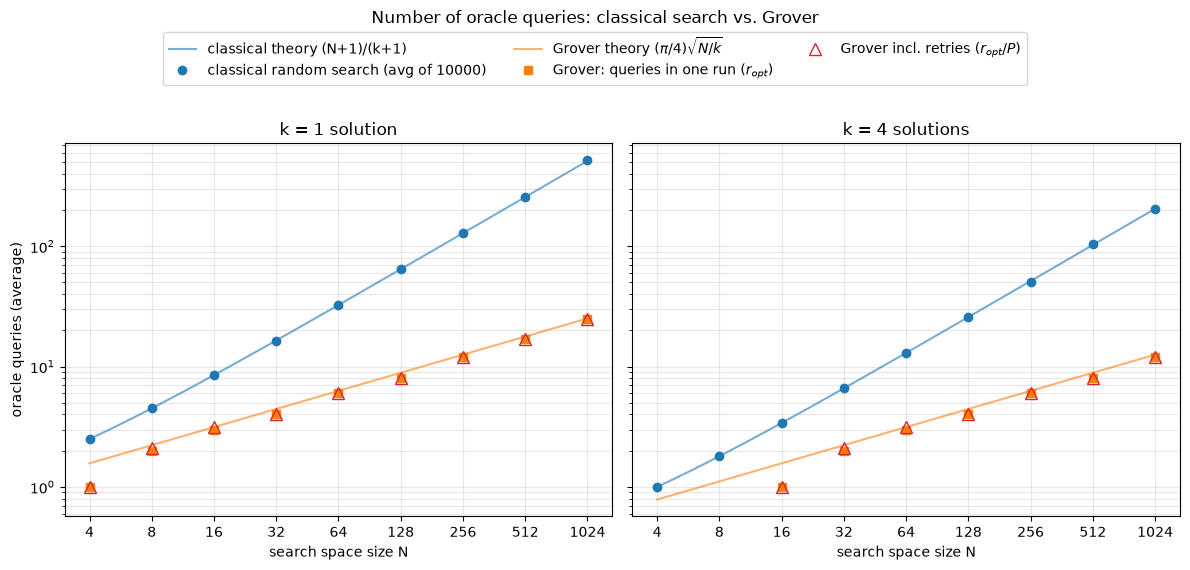

In [9]:
N_fine = np.logspace(np.log2(4), np.log2(1024), 200, base=2)
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(12, 5), sharey=True)
for ax, k in zip(axes, K_VALUES):
    cl = np.array([m for m, _ in classical[k]])
    r_opt = np.array([r for r, _, _ in grover_q[k]], dtype=float)
    r_over_p = np.array([rp for _, _, rp in grover_q[k]])
    Ns = np.array(N_VALUES)
    pos = r_opt > 0          # log scale can't show 0

    ax.plot(N_fine, (N_fine + 1) / (k + 1), "-", color="tab:blue", alpha=0.6, label="classical theory (N+1)/(k+1)")
    ax.plot(Ns, cl, "o", color="tab:blue", label=f"classical random search (avg of {TRIALS})")
    ax.plot(N_fine, np.pi / 4 * np.sqrt(N_fine / k), "-", color="tab:orange", alpha=0.6, label=r"Grover theory $(\pi/4)\sqrt{N/k}$")
    ax.plot(Ns[pos], r_opt[pos], "s", color="tab:orange", label="Grover: queries in one run ($r_{opt}$)")
    ax.plot(Ns[pos], r_over_p[pos], "^", color="tab:red", mfc="none", markersize=9, label="Grover incl. retries ($r_{opt}/P$)")

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(N_VALUES)
    ax.set_xticklabels([str(N) for N in N_VALUES])
    ax.set_xlabel("search space size N")
    ax.set_title(f"k = {k} solution{'s' if k > 1 else ''}")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("oracle queries (average)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.1))
fig.suptitle("Number of oracle queries: classical search vs. Grover", y=1.13)
plt.tight_layout()
plt.savefig("figures/fig_classical_comparison_queries.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
rows = ["| k | N | classical (simulated) | Grover $r_{opt}$ | Grover $P$ | Grover $r_{opt}/P$ | Grover with check $(r_{opt}+1)/P$ | speed-up |",
        "|---|---|---|---|---|---|---|---|"]
for k in K_VALUES:
    for N in [4, 16, 64, 256, 1024]:
        i = N_VALUES.index(N)
        m, _ = classical[k][i]
        r, P, rp = grover_q[k][i]
        speedup = f"{m / rp:.1f}×" if rp > 0 else "–"
        rows.append(f"| {k} | {N} | {m:.1f} | {r} | {P:.3f} | {rp:.2f} | {(r + 1) / P:.2f} | {speedup} |")
display(Markdown("\n".join(rows)))

| k | N | classical (simulated) | Grover $r_{opt}$ | Grover $P$ | Grover $r_{opt}/P$ | Grover with check $(r_{opt}+1)/P$ | speed-up |
|---|---|---|---|---|---|---|---|
| 1 | 4 | 2.5 | 1 | 1.000 | 1.00 | 2.00 | 2.5× |
| 1 | 16 | 8.5 | 3 | 0.961 | 3.12 | 4.16 | 2.7× |
| 1 | 64 | 32.2 | 6 | 0.997 | 6.02 | 7.02 | 5.4× |
| 1 | 256 | 129.3 | 12 | 1.000 | 12.00 | 13.00 | 10.8× |
| 1 | 1024 | 518.3 | 25 | 0.999 | 25.01 | 26.01 | 20.7× |
| 4 | 4 | 1.0 | 0 | 1.000 | 0.00 | 1.00 | – |
| 4 | 16 | 3.4 | 1 | 1.000 | 1.00 | 2.00 | 3.4× |
| 4 | 64 | 13.0 | 3 | 0.961 | 3.12 | 4.16 | 4.2× |
| 4 | 256 | 50.8 | 6 | 0.997 | 6.02 | 7.02 | 8.4× |
| 4 | 1024 | 203.6 | 12 | 1.000 | 12.00 | 13.00 | 17.0× |